Dataset
Netflix Titles
8,790 rows · 10 original columns

Analysis
Python + Pandas

Visualization
Matplotlib + Seaborn

Dashboard
Power BI (optional)

Final deliverable
Business report
# Step 1. Complete exploratory data analysis

In [6]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns 

In [7]:
df=pd.read_csv("netflix_cleaned.csv")
df.shape

(8790, 10)

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: int64(1), object(9)
memory usage: 686.8+ KB


# Step 2: Identify key content trends and patterns

In [10]:
df.astype(str).apply(lambda col:col.str.strip().eq('').sum())

show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

In [11]:
df=df.astype("object")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   object
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: object(10)
memory usage: 686.8+ KB


In [12]:
df=df.astype({col:"string" for col in df.select_dtypes(include="object").columns} )

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   string
 1   type          8790 non-null   string
 2   title         8790 non-null   string
 3   director      8790 non-null   string
 4   country       8790 non-null   string
 5   date_added    8790 non-null   string
 6   release_year  8790 non-null   string
 7   rating        8790 non-null   string
 8   duration      8790 non-null   string
 9   listed_in     8790 non-null   string
dtypes: string(10)
memory usage: 686.8 KB


In [14]:
df["date_added"]=pd.to_datetime(df["date_added"])

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   show_id       8790 non-null   string        
 1   type          8790 non-null   string        
 2   title         8790 non-null   string        
 3   director      8790 non-null   string        
 4   country       8790 non-null   string        
 5   date_added    8790 non-null   datetime64[ns]
 6   release_year  8790 non-null   string        
 7   rating        8790 non-null   string        
 8   duration      8790 non-null   string        
 9   listed_in     8790 non-null   string        
dtypes: datetime64[ns](1), string(9)
memory usage: 686.8 KB


In [16]:
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


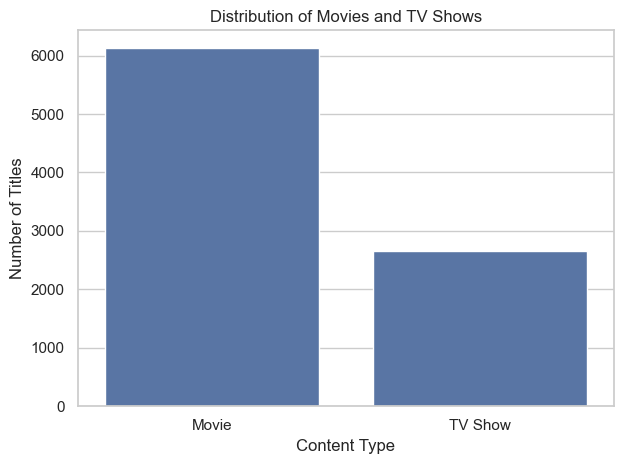

In [17]:
sns.set_theme(style="whitegrid")
sns.countplot(data=df,x="type")
plt.title("Distribution of Movies and TV Shows")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.show()

# Step 3: Develop multiple visual dashboards

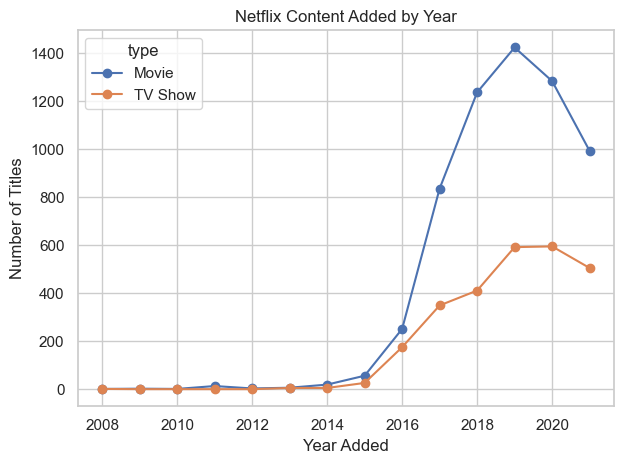

In [18]:
df["added_year"] = df["date_added"].dt.year

added_trend = (
    df.dropna(subset=["added_year"])
      .groupby(["added_year", "type"])
      .size()
      .unstack(fill_value=0)
)

added_trend.plot(marker="o")
plt.title("Netflix Content Added by Year")
plt.xlabel("Year Added")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.show()

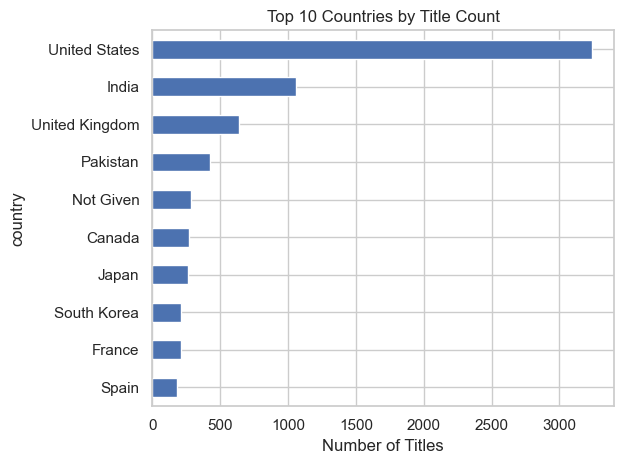

In [19]:
country_counts = (
    df["country"].dropna()
      .str.split(", ").explode()
      .str.strip().value_counts()
      .head(10)
)

country_counts.sort_values().plot(kind="barh")
plt.title("Top 10 Countries by Title Count")
plt.xlabel("Number of Titles")
plt.tight_layout()
plt.show()

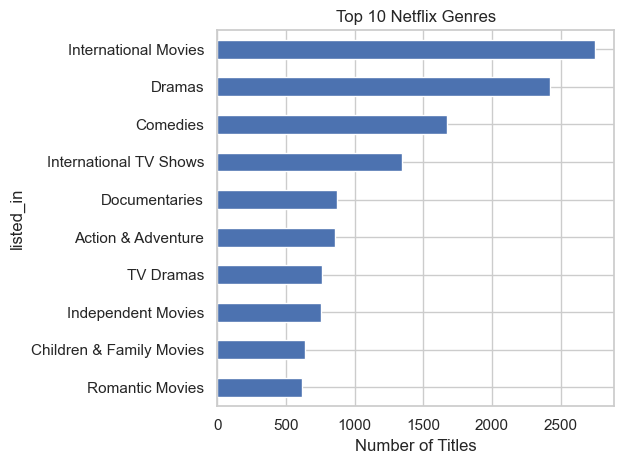

In [20]:
genre_counts = (
    df["listed_in"].dropna()
      .str.split(", ").explode()
      .str.strip().value_counts()
      .head(10)
)

genre_counts.sort_values().plot(kind="barh")
plt.title("Top 10 Netflix Genres")
plt.xlabel("Number of Titles")
plt.tight_layout()
plt.show()

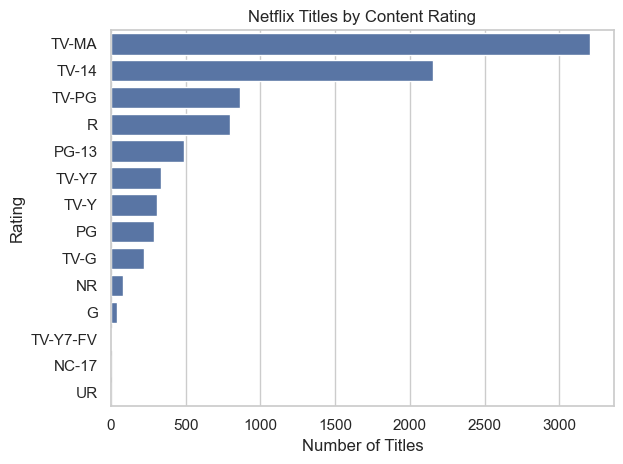

In [21]:
rating_counts = df["rating"].value_counts()

sns.barplot(
    x=rating_counts.values,
    y=rating_counts.index
)
plt.title("Netflix Titles by Content Rating")
plt.xlabel("Number of Titles")
plt.ylabel("Rating")
plt.tight_layout()
plt.show()

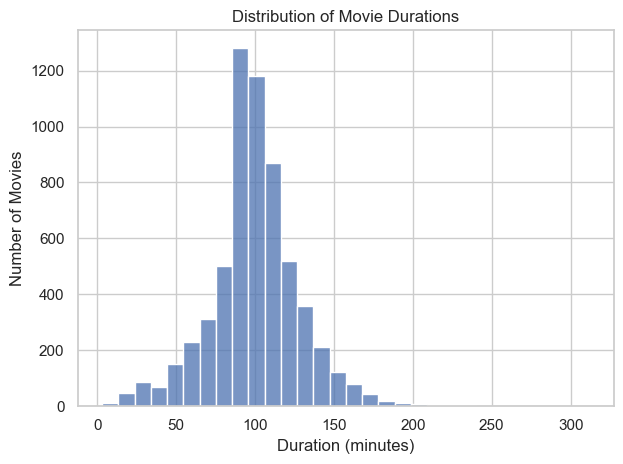

count       6126.0
mean     99.584884
std      28.283225
min            3.0
25%           87.0
50%           98.0
75%          114.0
max          312.0
Name: duration_minutes, dtype: Float64


In [22]:
movies = df[df["type"] == "Movie"].copy()

movies["duration_minutes"] = pd.to_numeric(
    movies["duration"].str.extract(r"(\d+)")[0],
    errors="coerce"
)

sns.histplot(
    data=movies,
    x="duration_minutes",
    bins=30
)
plt.title("Distribution of Movie Durations")
plt.xlabel("Duration (minutes)")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()

print(movies["duration_minutes"].describe())

# Step 4: Generate actionable business insights

Netflix Business Insights
1. Content Distribution: Movies account for 69.69% of titles, while TV shows represent 30.31%.

2. Top Countries: The United States leads with 3,240 titles, followed by India with 1,057.

3. Popular Genres: International Movies and Dramas are the most frequently listed categories.

4. Release Trends: 2018 is the most represented release year, with 1,146 titles.

5. Movie Duration: The median movie duration is 98 minutes.

6. Business Recommendation: Analyze audience engagement, regional preferences, and genre performance to improve content planning.

7. Data Quality: Check placeholder values such as “Not Given” to ensure accurate analysis.

# Step 5: Prepare and present the final analytical report

# Netflix Business Insights Report

## 1. Introduction
This project analyzes Netflix's content dataset to identify trends and generate actionable business insights using Python, Pandas, Matplotlib, and Seaborn.

## 2. Dataset Overview
The dataset contains 8,790 titles and 10 columns, including content type, title, country, release year, rating, duration, and genre.

## 3. Key Findings
- Movies represent 69.69% of the catalog, while TV shows account for 30.31%.
- The United States has the highest country count, followed by India.
- International Movies and Dramas are the most frequently listed genres.
- 2018 is the most represented release year, with 1,146 titles.
- The median movie duration is 98 minutes.

## 4. Dashboard Summary
Three dashboards were planned to present content distribution, country and genre analysis, and content trends. Visualizations include bar charts, line charts, a movie-duration histogram, a TV-show seasons chart, and a geographic map.

## 5. Business Recommendations
- Analyze audience engagement to evaluate movies versus TV shows.
- Investigate regional content preferences and genre performance.
- Compare release years with Netflix addition dates.
- Examine movie duration alongside viewing completion rates.
- Clean placeholder values such as “Not Given” to improve data quality.

## 6. Conclusion
The analysis provides useful insights into Netflix's catalog composition, genre distribution, geographic representation, and release trends. These findings can support further content planning. However, viewing and revenue data are needed to confirm audience preferences and commercial performance.